# Harmonization of MODIS and VIIRS active-fire detections — Central Asia

This notebook documents how MODIS (Terra/Aqua, 1 km, 2000–present) and VIIRS (375 m, S-NPP 2012–present) active-fire detections from NASA FIRMS are merged into a single, sensor-independent monthly fire-count series on a 0.25° grid for Kazakhstan, Kyrgyzstan, Uzbekistan, Tajikistan and Turkmenistan.

All logic lives in [`src/harmonize.py`](../src/harmonize.py); the notebook calls it and shows the results.
Raw data are downloaded with `scripts/download.py`; `scripts/process.py` runs the same pipeline end to end.

**Target unit:** number of VIIRS S-NPP 375 m detections per cell per month ("VIIRS-equivalent fire count").

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import harmonize as H
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
pts = pd.read_parquet(ROOT / "data/processed/points.parquet")
print(f"{len(pts):,} filtered detections, {pts.date.min()} .. {pts.date.max()}")
pts.groupby("sensor", observed=True).size().rename("detections").to_frame()

3,880,666 filtered detections, 2001-01-04 .. 2026-11-15


,detections
sensor,
MODIS,1221801
VIIRS_NOAA20,838086
VIIRS_NOAA21,119056
VIIRS_SNPP,1701723


## 1. Filtering

| rule | why |
|---|---|
| MODIS `confidence >= 30` | drops low-confidence MODIS pixels (FIRMS recommendation for "nominal" and "high") |
| VIIRS `confidence in {nominal, high}` | VIIRS low-confidence pixels are often sun glint or hot bare surfaces |
| `type == 0` (presumed vegetation fire) | removes volcanoes (1), static land sources such as gas flares and industry (2) and offshore (3) |
| NRT points without `type` | dropped if within ~1 km (0.01° cell + neighbours) of an archive static source, and clipped to the five countries |

Kazakhstan and Turkmenistan have many oil and gas flares (Mangystau, Atyrau, Tengiz, Karachaganak), so the static-source filter matters: it removes fires that never change with the season and would otherwise dominate winter months.

In [2]:
g = H.grid_monthly(pts)
print(f"{len(g):,} non-empty cell-months, {g[['row','col']].drop_duplicates().shape[0]:,} cells of {H.CELL} deg")
ann = g.groupby("year")[["terra", "aqua", "modis", "viirs", "noaa20", "noaa21"]].sum()
ann

244,381 non-empty cell-months, 6,316 cells of 0.25 deg


stream,terra,aqua,modis,viirs,noaa20,noaa21
year,,,,,,
2001,33680,0,33680,0,0,0
2002,61296,41599,102895,0,0,0
2003,47693,54584,102277,0,0,0
2004,47136,49286,96422,0,0,0
2005,34713,35298,70011,0,0,0
2006,38219,37835,76054,0,0,0
2007,26723,28444,55167,0,0,0
2008,35856,37722,73578,0,0,0
2009,20112,21139,41251,0,0,0


## 2. The problem: two sensors, two levels

VIIRS 375 m resolves much smaller fires than MODIS 1 km, so it reports roughly 3–5× more detections over the same fires. Simply appending VIIRS to MODIS in 2012 would create an artificial jump. In addition, Aqua MODIS only starts in July 2002, so 2001–mid-2002 is Terra-only.

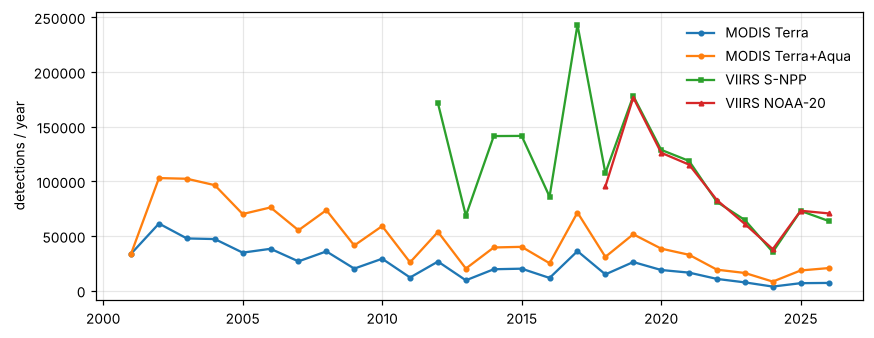

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(ann.index, ann.terra, "o-", ms=3, label="MODIS Terra")
ax.plot(ann.index, ann.modis, "o-", ms=3, label="MODIS Terra+Aqua")
ax.plot(ann.index[ann.index >= 2012], ann.viirs[ann.index >= 2012], "s-", ms=3, label="VIIRS S-NPP")
ax.plot(ann.index[ann.index >= 2018], ann.noaa20[ann.index >= 2018], "^-", ms=3, label="VIIRS NOAA-20")
ax.set_ylabel("detections / year"); ax.legend(frameon=False); ax.grid(alpha=.3)

## 3. Terra-only months (2001 – July 2002)

For months before August 2002 only Terra exists. We estimate, for each calendar month, the factor (Terra+Aqua)/Terra over 2003–2011 and scale Terra-only counts by it before harmonization. Afternoon (Aqua 13:30) overpasses see more fires than morning ones, so the factor is > 1 and seasonal.

In [4]:
tf = H.terra_only_factor(g)
tf.round(2).to_frame().T

month,1,2,3,4,5,6,7,8,9,10,11,12
terra_factor,3.44,3.23,2.46,2.14,1.92,1.79,1.81,1.92,2.08,2.37,2.93,2.92


## 4. Candidate models (MODIS → VIIRS-equivalent)

All models are fitted on cell-months of the overlap period where at least one sensor saw a fire.

1. **Monthly ratio** — $\hat V = k_m M$, with $k_m = \sum V / \sum M$ for calendar month $m$. Preserves regional totals by construction.
2. **Seasonal log-linear regression** — $\log(1+V) = a_m + b_m \log(1+M)$, OLS per calendar month on cells with $M>0$, back-transformed with Duan's smearing estimator.
3. **Cell × season ratio (empirical Bayes)** — $\hat V = k_m\, r_c\, M$, where $r_c = (\sum_c V + \alpha)/(\sum_c k_m M + \alpha)$ is a per-cell factor shrunk toward 1. It captures that the VIIRS/MODIS ratio is higher where fires are small (cropland stubble burning) than where they are large (steppe wildfires). $\alpha$ is chosen by an inner year-split inside the training period.

**Validation:** year-blocked split — train 2012–2018, test 2019–2025 — so the test mimics applying the model to years it has not seen.

In [5]:
results, cv = H.cross_validate(g)
best = H.best_model_name(results)
tab = pd.DataFrame(results).T[["cell_month_MAE", "cell_month_RMSE", "cell_month_r", "cell_month_bias_pct",
                               "regional_month_MAE", "regional_month_r", "annual_abs_pct_error"]]
print("best model:", best, "| alpha =", results[best].get("alpha"))
tab.round(3)

best model: cell_seasonal_ratio | alpha = 1000


,cell_month_MAE,cell_month_RMSE,cell_month_r,cell_month_bias_pct,regional_month_MAE,regional_month_r,annual_abs_pct_error
monthly_ratio,6.837,16.583,0.862,-9.031,919.125,0.985,12.842
loglinear_seasonal,7.284,22.337,0.850,-2.403,1324.662,0.976,14.029
cell_seasonal_ratio,6.746,16.271,0.867,-9.089,905.646,0.985,12.671
no_adjustment,8.414,26.141,0.860,-72.828,5887.357,0.971,73.784


**Reading the table.** All three models cut the cell-month error relative to using MODIS counts unadjusted (MAE 8.4 → 6.7–7.3) and remove the −73 % level bias. The cell × season ratio has the lowest cell-month MAE and RMSE, the highest correlation, and the lowest annual-total error, so it is the model used. The remaining −8 % bias in the test years is consistent with the orbital drift of Terra and Aqua after 2020 (later overpass times, fewer MODIS detections), which a model trained on 2012–2018 cannot know about. It affects only the 2019–2025 validation, not the 2001–2011 reconstruction, which uses MODIS from its stable-orbit period.

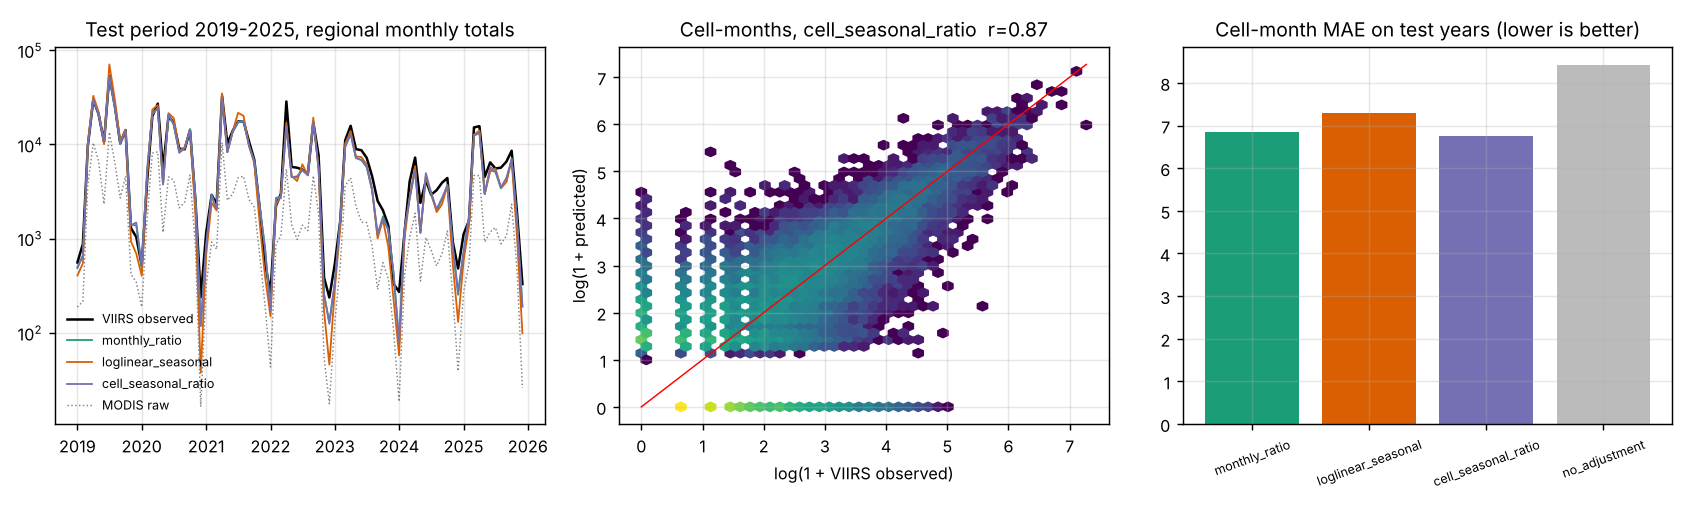

In [6]:
from IPython.display import Image
Image(str(ROOT / "docs/figures/validation.png"))

## 5. Spatial pattern of the VIIRS/MODIS ratio

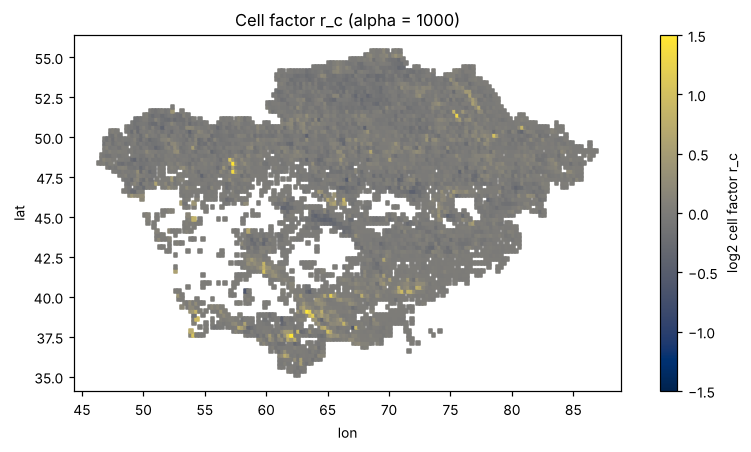

In [7]:
model = H.CellSeasonalRatio().fit(H.complete_overlap(g, range(2012, 2026)))
r = model.r.reset_index(); r.columns = ["row", "col", "r"]
lat, lon = H.cell_center(r.row, r.col)
fig, ax = plt.subplots(figsize=(9, 4.2))
sc = ax.scatter(lon, lat, c=np.log2(r.r), s=6, marker="s", cmap="cividis", vmin=-1.5, vmax=1.5)
cb = plt.colorbar(sc, ax=ax); cb.set_label("log2 cell factor r_c")
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.set_title(f"Cell factor r_c (alpha = {model.alpha})"); ax.set_aspect(1.3)

## 6. S-NPP gaps after 2012

From 2012 the series is VIIRS S-NPP itself. When S-NPP has an outage or the near-real-time feed lags (regional S-NPP total < 70 % of NOAA-20 in that month), NOAA-20 counts are used instead, scaled by the 2019–2025 S-NPP/NOAA-20 ratio. NOAA-20 carries the same VIIRS instrument, so this is a near one-to-one substitution.

In [8]:
harm, _ = H.harmonize(g, best)
harm.groupby(["year", "month", "source"])["count"].sum().reset_index().query("source != 'VIIRS S-NPP' and year >= 2012")

,year,month,source,count
282,2024,7,VIIRS NOAA-20 (S-NPP gap fill),4874.562500
306,2026,7,VIIRS NOAA-20 (S-NPP gap fill),8343.118164
310,2026,11,VIIRS NOAA-20 (S-NPP gap fill),1393.886475


## 7. Result: one continuous series

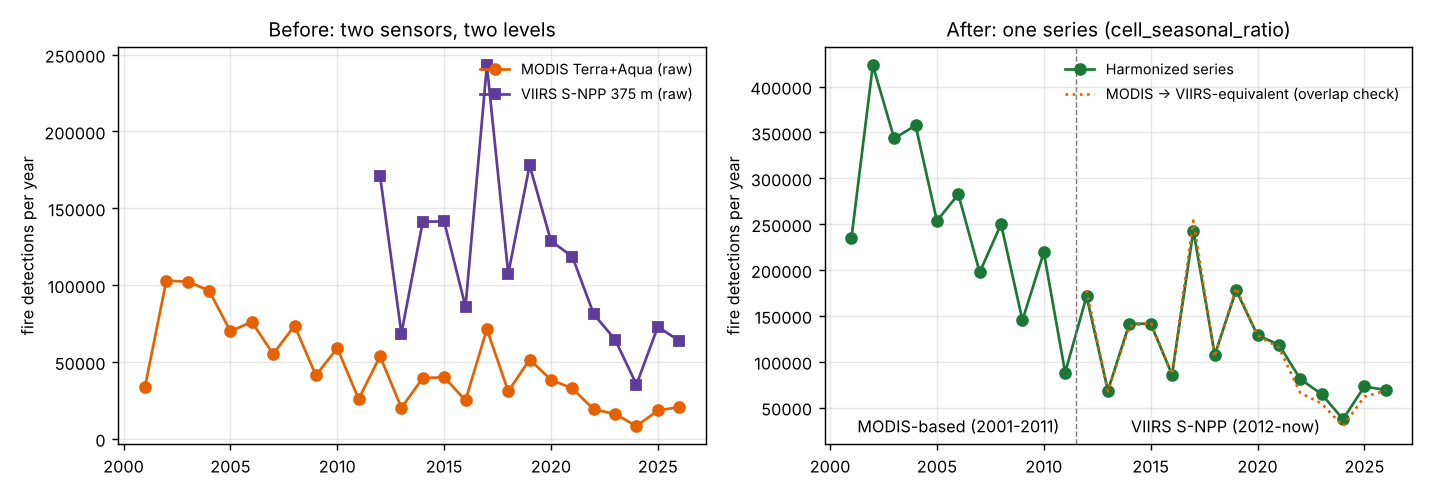

In [9]:
Image(str(ROOT / "docs/figures/before_after.png"))

In [10]:
hy = harm.groupby(["year", "source"])["count"].sum().unstack(fill_value=0).round(0)
hy

source,MODIS Terra (harmonized),MODIS Terra+Aqua (harmonized),VIIRS NOAA-20 (S-NPP gap fill),VIIRS S-NPP
year,,,,
2001,235211.0,0.0,0.0,0.0
2002,107558.0,315730.0,0.0,0.0
2003,0.0,343493.0,0.0,0.0
2004,0.0,357719.0,0.0,0.0
2005,0.0,253620.0,0.0,0.0
2006,0.0,282601.0,0.0,0.0
2007,0.0,197441.0,0.0,0.0
2008,0.0,250002.0,0.0,0.0
2009,0.0,145200.0,0.0,0.0


## 8. Limitations

* Counts are **detections**, not burned area or fire events; one large fire produces many detections.
* MODIS cell-months with zero detections stay zero after conversion, so very small fires that only VIIRS would have seen before 2012 are under-represented at the cell level (regional totals are corrected through $k_m$, cell totals partly through $r_c$).
* The model assumes the cell-level VIIRS/MODIS relationship is stable in time; land-use change between the 2000s and 2010s (e.g. less stubble burning) can bias individual cells.
* Terra/Aqua orbital drift after 2020 lowers MODIS counts; this does not affect the series (VIIRS is used after 2012) but shows up as −8 % bias in validation.
* The grid is 0.25°; areas smaller than a cell are approximated by the share of each cell's area inside the area of interest.